# Practical 4 — Dimensionality Reduction, Geometric Learning & Clustering

**Machine Learning for Bioinformatics**

## Student challenge

You will use similiar microscopic dataset - but extended version.
>week4\all_sources_isc_vgg_embeddings.csv

Source - will include additional info both on test and cell type


### Your task
1. Diagnose dataset using PCA - checking presense of batches/techninical variables in the data.

2. Compare UMAP/tsne/pca projection
3. Validate those plots against present labels


4. Train and evaluate a KNN and SVM model - to predict label, and interpret the results

5. Perform clustering analysis using 2 distict methods and compare clustring results with present labels.

6. Try to decode label meaning

## Set up

In [132]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap.umap_ as umap
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from pathlib import Path

from sklearn.metrics import silhouette_score

RANDOM_STATE = 300926


## Load Data

In [133]:
df = pd.read_csv("all_sources_isc_vgg_embeddings.tar.gz", compression="gzip")

In [134]:
df

,./all_sources_isc_vgg_embeddings.csv,label,Value,vgg_0,vgg_1,vgg_2,vgg_3,vgg_4,vgg_5,vgg_6,...,vgg_502,vgg_503,vgg_504,vgg_505,vgg_506,vgg_507,vgg_508,vgg_509,vgg_510,vgg_511
0,mtt,C,94.774444,0.011359,0.241203,0.344854,0.000000,11.211005,0.004637,0.0,...,0.188881,0.0,0.954637,2.482550,0.000000,0.118003,0.000000,0.000000,1.703285,0.000000
1,mtt,C,94.774444,0.025853,0.000000,1.069848,0.000000,11.320415,0.000000,0.0,...,0.000000,0.0,0.168406,6.162180,0.000000,0.107752,0.000000,0.271620,4.474264,0.000000
2,mtt,C,94.774444,0.480963,0.000000,3.107252,0.000000,4.831994,0.064862,0.0,...,0.124030,0.0,0.665731,1.306546,0.030879,0.144269,0.005907,0.232978,1.154307,0.000000
3,mtt,C,94.774444,0.000000,0.000000,0.058814,0.000000,6.624664,0.000000,0.0,...,0.316281,0.0,0.318968,0.330109,0.480029,0.542135,0.000000,0.008872,3.581180,0.289227
4,mtt,C,94.774444,0.000000,0.000000,0.119758,0.000000,8.961069,0.000000,0.0,...,0.099849,0.0,0.034700,1.626213,0.012560,0.605835,0.000000,0.025230,1.533522,0.180085
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23841,study18,S,NaN,0.000000,0.000000,1.000184,0.000000,0.740112,0.000000,0.0,...,0.434452,0.0,0.000000,0.732429,0.000000,0.662563,0.000000,0.000000,0.678243,0.000000
23842,study18,S,NaN,0.000000,0.000000,0.677755,0.000000,2.872867,0.000000,0.0,...,2.191196,0.0,0.023503,0.882949,0.000000,0.059748,0.000000,0.000000,0.889415,0.000000
23843,study18,S,NaN,0.000000,0.000000,0.020610,0.000000,2.368106,0.035866,0.0,...,0.834328,0.0,0.051658,0.039791,4.803977,0.000000,0.000000,0.000000,1.185690,0.000000
23844,study18,S,NaN,0.000000,0.000000,0.311633,0.036931,1.409468,0.000000,0.0,...,0.874173,0.0,0.000000,0.000000,0.000000,0.563039,0.000000,0.000000,1.692470,0.000000


## EDA and Data Preperation

In [135]:
df.shape

(23846, 515)

In [136]:
df_clean = df.dropna(subset=['vgg_0']).copy()
df_clean.shape

(23845, 515)

In [137]:
missing_vals = df_clean.isna().sum()
print(missing_vals[missing_vals > 0])

Value    22863
dtype: int64


We retain rows with missing Value entries because our models only need VGG features and labels, using Value only for the final biological interpretation.

In [138]:
print(f"Number of exact duplicate rows: {df_clean.duplicated().sum()}")

Number of exact duplicate rows: 1


In [139]:
df_clean = df_clean.drop_duplicates()

In [140]:
print(df_clean['label'].value_counts(dropna=False))

label
I    11977
C    11591
S      276
Name: count, dtype: int64


In [141]:
source_col = df_clean.columns[0]
source_col

'./all_sources_isc_vgg_embeddings.csv'

In [142]:
metadata = df_clean[[source_col, 'label', 'Value']]
metadata

,./all_sources_isc_vgg_embeddings.csv,label,Value
0,mtt,C,94.774444
1,mtt,C,94.774444
2,mtt,C,94.774444
3,mtt,C,94.774444
4,mtt,C,94.774444
...,...,...,...
23840,study18,S,NaN
23841,study18,S,NaN
23842,study18,S,NaN
23843,study18,S,NaN


In [143]:
print(df_clean[source_col].value_counts(dropna=False))

./all_sources_isc_vgg_embeddings.csv
jimt       21848
study18     1001
alamar       553
mtt          429
chroma        13
Name: count, dtype: int64


In [144]:
vgg_columns = [col for col in df_clean.columns if col.startswith('vgg_')]
print(vgg_columns)

['vgg_0', 'vgg_1', 'vgg_2', 'vgg_3', 'vgg_4', 'vgg_5', 'vgg_6', 'vgg_7', 'vgg_8', 'vgg_9', 'vgg_10', 'vgg_11', 'vgg_12', 'vgg_13', 'vgg_14', 'vgg_15', 'vgg_16', 'vgg_17', 'vgg_18', 'vgg_19', 'vgg_20', 'vgg_21', 'vgg_22', 'vgg_23', 'vgg_24', 'vgg_25', 'vgg_26', 'vgg_27', 'vgg_28', 'vgg_29', 'vgg_30', 'vgg_31', 'vgg_32', 'vgg_33', 'vgg_34', 'vgg_35', 'vgg_36', 'vgg_37', 'vgg_38', 'vgg_39', 'vgg_40', 'vgg_41', 'vgg_42', 'vgg_43', 'vgg_44', 'vgg_45', 'vgg_46', 'vgg_47', 'vgg_48', 'vgg_49', 'vgg_50', 'vgg_51', 'vgg_52', 'vgg_53', 'vgg_54', 'vgg_55', 'vgg_56', 'vgg_57', 'vgg_58', 'vgg_59', 'vgg_60', 'vgg_61', 'vgg_62', 'vgg_63', 'vgg_64', 'vgg_65', 'vgg_66', 'vgg_67', 'vgg_68', 'vgg_69', 'vgg_70', 'vgg_71', 'vgg_72', 'vgg_73', 'vgg_74', 'vgg_75', 'vgg_76', 'vgg_77', 'vgg_78', 'vgg_79', 'vgg_80', 'vgg_81', 'vgg_82', 'vgg_83', 'vgg_84', 'vgg_85', 'vgg_86', 'vgg_87', 'vgg_88', 'vgg_89', 'vgg_90', 'vgg_91', 'vgg_92', 'vgg_93', 'vgg_94', 'vgg_95', 'vgg_96', 'vgg_97', 'vgg_98', 'vgg_99', 'vgg_100'

In [145]:
X = df_clean[vgg_columns].values

In [146]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [147]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

1. Оne observation: single microscopic cell crop.
2. One feature: single VGG neural network embedding dimension
3. The values are VGG neural network embeddings that are standardized before applying PCA.

## 1. Diagnose dataset using PCA

### PCA

In [148]:
pca = PCA(n_components=30, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print(f"Explained variance by PC1 and PC2: {pca.explained_variance_ratio_[:2].sum():.3f}")

Explained variance by PC1 and PC2: 0.213


First two PCA components explain only 21.3% of the variance. It indicates that the dataset is highly complex, and the 2D projection captures only a small fraction of the total information.

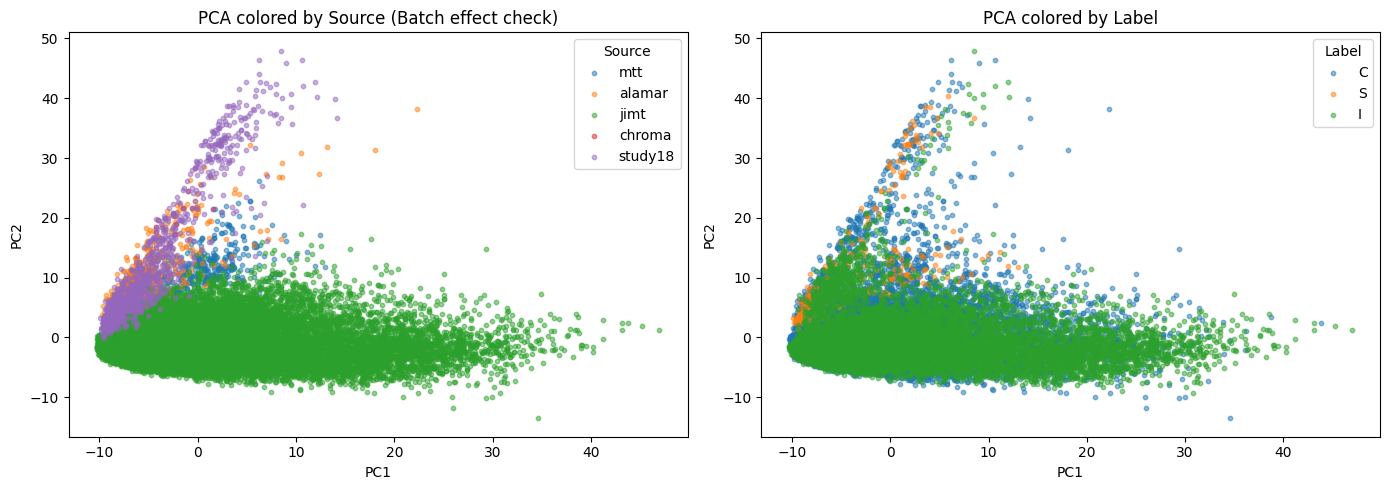

In [149]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#  by Source
for source in metadata[source_col].dropna().unique():
    mask = metadata[source_col] == source
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], alpha=0.5, s=10, label=source)
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("PCA colored by Source (Batch effect check)")
axes[0].legend(title="Source")

#  by Label
for lbl in metadata['label'].dropna().unique():
    mask = metadata['label'] == lbl
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], alpha=0.5, s=10, label=lbl)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("PCA colored by Label")
axes[1].legend(title="Label")

plt.tight_layout()
plt.show()

The left plot shows a strong technical batch effect: the observations form distinct structural clusters mostly based on their data source rather than their inherent characteristics.   

The right plot shows the biological classes (C, S, I) all mixed together, which means technical variations is hiding the true biological differences in these primary components.

80% of variance: 158 PCs
90% of variance: 264 PCs


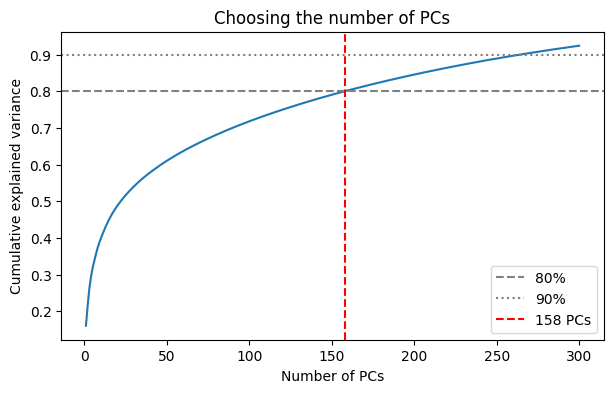

In [150]:
# Choose the number of PCs
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

for thr in (0.80, 0.90):
    print(f"{int(thr*100)}% of variance: {np.argmax(cum_var >= thr) + 1} PCs")

N_PCS = int(np.argmax(cum_var >= 0.80)) + 1

plt.figure(figsize=(7, 4))
plt.plot(range(1, 301), cum_var[:300])
plt.axhline(0.80, color="grey", ls="--", label="80%")
plt.axhline(0.90, color="grey", ls=":", label="90%")
plt.axvline(N_PCS, color="red", ls="--", label=f"{N_PCS} PCs")
plt.xlabel("Number of PCs"); plt.ylabel("Cumulative explained variance")
plt.title("Choosing the number of PCs"); plt.legend(); plt.show()

In [151]:
# Final PCA
pca = PCA(n_components=N_PCS, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("X_pca shape:", X_pca.shape)

X_pca shape: (23844, 158)


I retained 158 principal components, the minimum number explaining 80% of the total variance. This keeps most of the biological and technical signal while discarding the noisy low-variance tail.

## 2. Compare UMAP/tsne/pca projection

#### By Label

In [152]:
tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_pca)

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE)
X_umap = reducer.fit_transform(X_pca)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


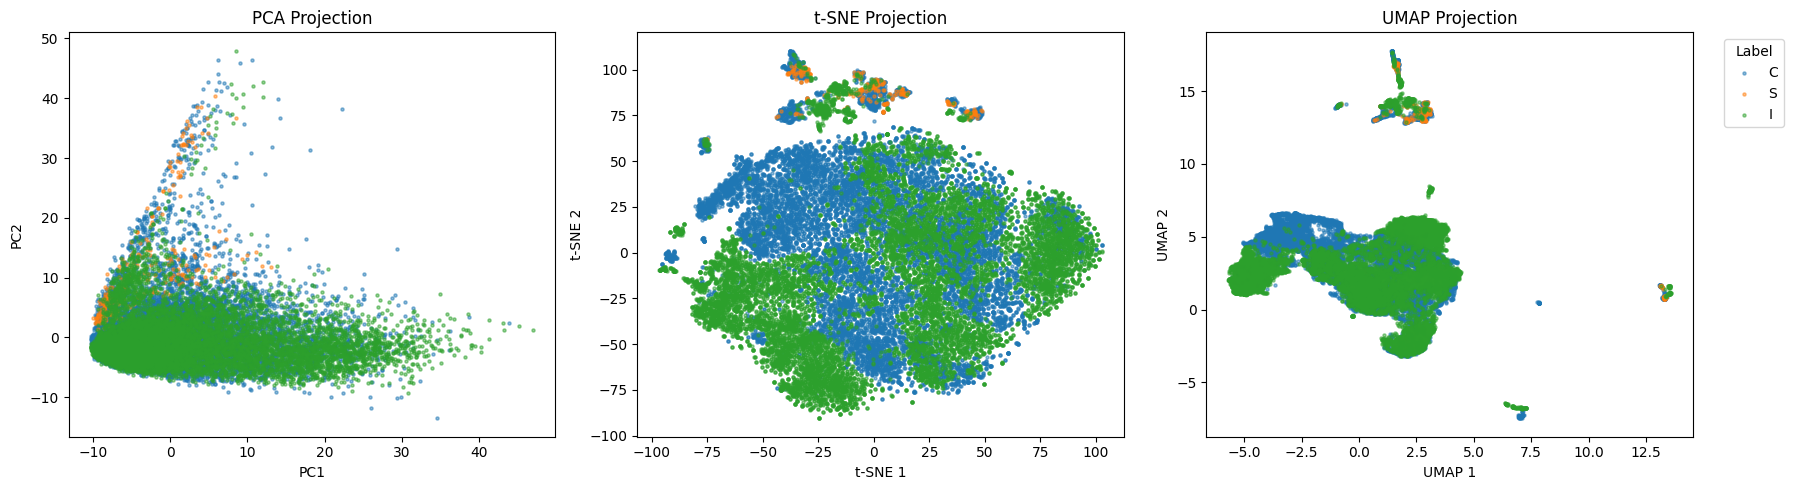

In [153]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

labels = metadata['label'].dropna().unique()

# PCA
for lbl in labels:
    mask = metadata['label'] == lbl
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], alpha=0.5, s=5, label=lbl)
axes[0].set_title('PCA Projection')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# t-SNE
for lbl in labels:
    mask = metadata['label'] == lbl
    axes[1].scatter(X_tsne[mask, 0], X_tsne[mask, 1], alpha=0.5, s=5, label=lbl)
axes[1].set_title('t-SNE Projection')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')

# UMAP
for lbl in labels:
    mask = metadata['label'] == lbl
    axes[2].scatter(X_umap[mask, 0], X_umap[mask, 1], alpha=0.5, s=5, label=lbl)
axes[2].set_title('UMAP Projection')
axes[2].set_xlabel('UMAP 1')
axes[2].set_ylabel('UMAP 2')

axes[2].legend(title='Label', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

#### By Source

we can see that while PCA shows a massive overlap of all biological labels, the non-linear projections reveal a more complex local topology, that linear PCA fails to separate.

t-SNE breaks the data into quite isolated islands, but the main biological classes still remain mixed together in the center.

UMAP also performed better than PCA successfully isolates a few specific sub-clusters belonging to the S label.

Overall, we have confirmed that the VGG features are highly similar.(especially I and C)

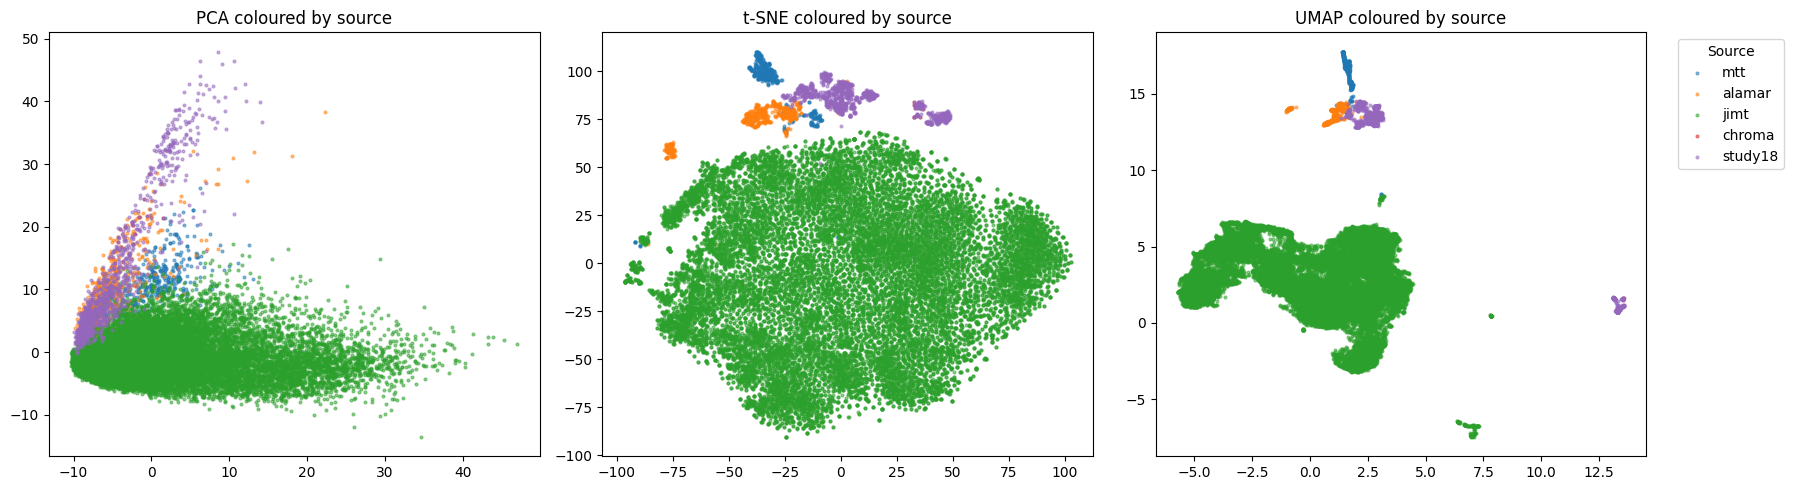

In [154]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, emb, title in zip(axes, [X_pca[:, :2], X_tsne, X_umap], ["PCA", "t-SNE", "UMAP"]):
    for s in metadata[source_col].unique():
        mk = (metadata[source_col] == s).values
        ax.scatter(emb[mk, 0], emb[mk, 1], s=4, alpha=0.5, label=s)
    ax.set_title(f"{title} coloured by source")
axes[2].legend(title="Source", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout(); plt.show()

linear PCA separates only the massive jimt source, while mixing the other minority sources together.  

t-SNE clearly breaks these minority data sources into isolated islands at the top, physically separating them from the main jimt cloud that dominates the center.   

UMAP also isolates the smaller data batches into very distinct, tight sub-clusters located entirely outside the primary dataset.   

Overall, we have confirmed a significant technical batch effect, as the algorithms (especially non-linear ones) naturally cluster the data based on its source origin rather than just biological characteristics.

## 3. Validate those plots against present labels

In [155]:
valid_mask = metadata['label'].notna()
labels_valid = metadata['label'][valid_mask]

X_pca_valid = X_pca[valid_mask, :2]
X_tsne_valid = X_tsne[valid_mask]
X_umap_valid = X_umap[valid_mask]

In [174]:
score_pca = silhouette_score(X_pca_valid, labels_valid)
print(f"PCA Silhouette Score:  {score_pca:.4f}")

score_tsne = silhouette_score(X_tsne_valid, labels_valid)
print(f"t-SNE Silhouette Score:     {score_tsne:.4f}")

score_umap = silhouette_score(X_umap_valid, labels_valid)
print(f"UMAP Silhouette Score:      {score_umap:.4f}")

PCA Silhouette Score:  -0.0108
t-SNE Silhouette Score:     -0.0318
UMAP Silhouette Score:      0.0058


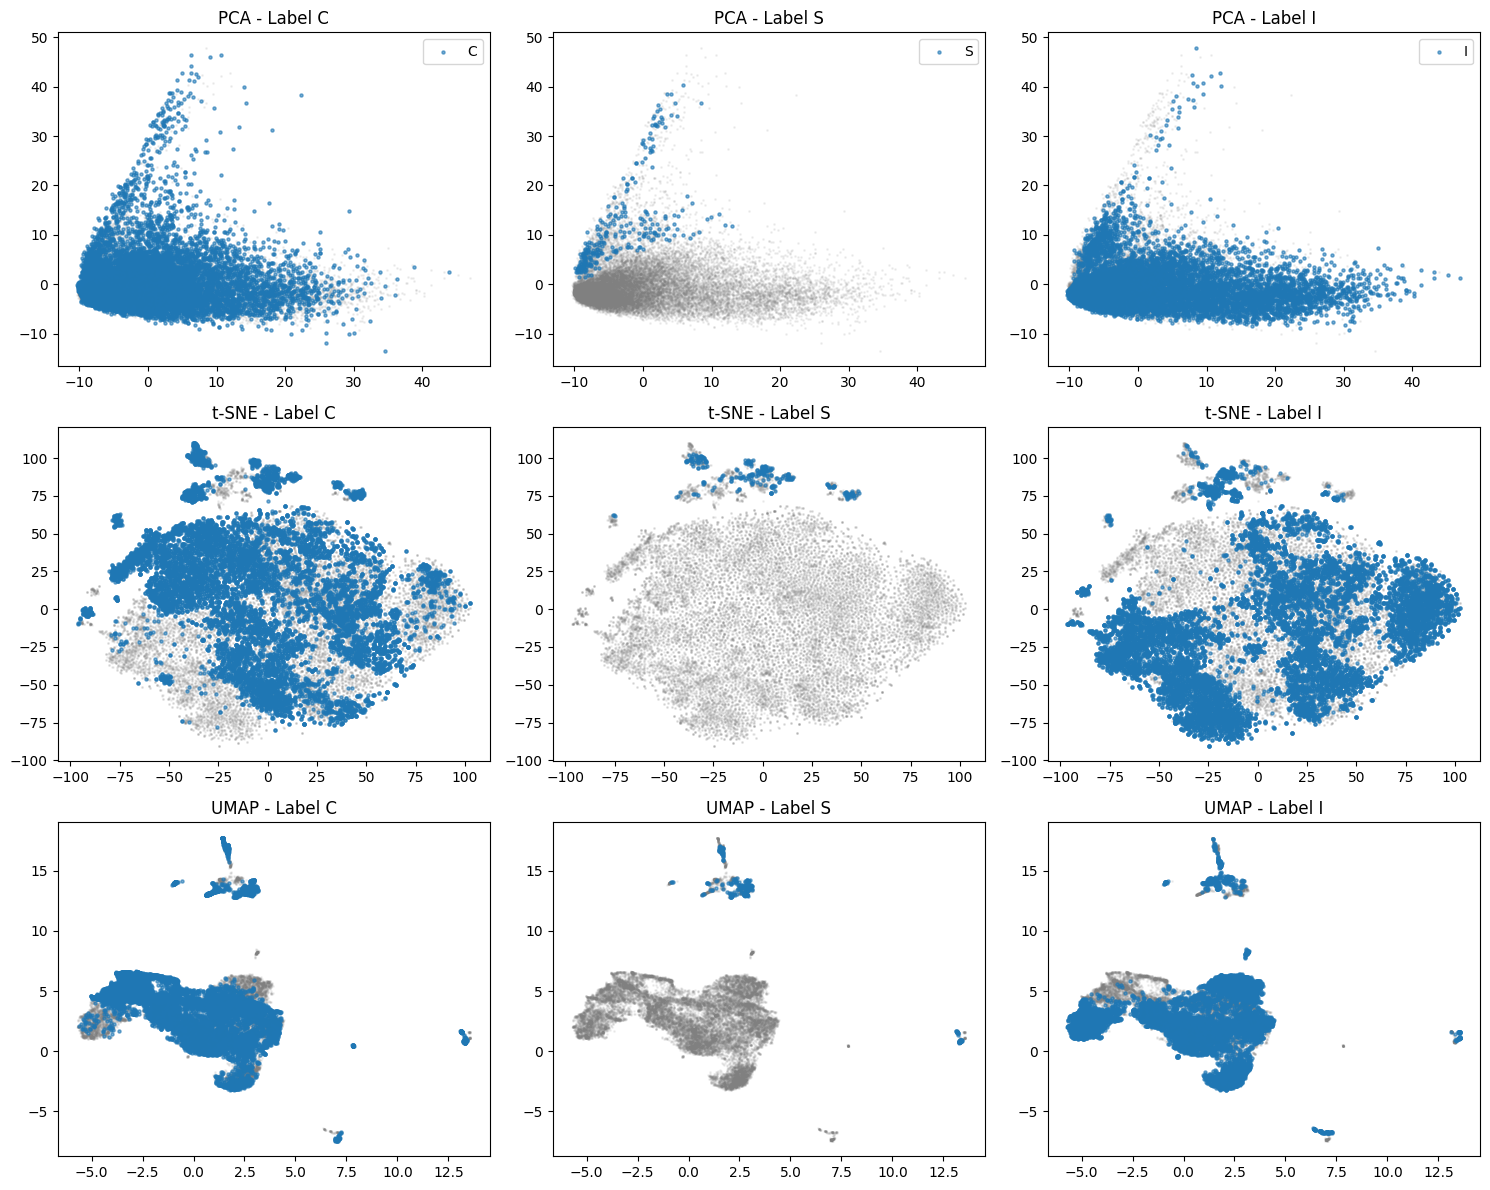

In [157]:
unique_labels = labels_valid.unique()
fig, axes = plt.subplots(3, len(unique_labels), figsize=(5 * len(unique_labels), 12))

for i, lbl in enumerate(unique_labels):
    mask = (labels_valid == lbl)

    axes[0, i].scatter(X_pca_valid[~mask, 0], X_pca_valid[~mask, 1], alpha=0.1, s=1, c='gray')
    axes[0, i].scatter(X_pca_valid[mask, 0], X_pca_valid[mask, 1], alpha=0.6, s=5, label=lbl)
    axes[0, i].set_title(f"PCA - Label {lbl}")
    axes[0, i].legend()

    axes[1, i].scatter(X_tsne_valid[~mask, 0], X_tsne_valid[~mask, 1], alpha=0.1, s=1, c='gray')
    axes[1, i].scatter(X_tsne_valid[mask, 0], X_tsne_valid[mask, 1], alpha=0.6, s=5, label=lbl)
    axes[1, i].set_title(f"t-SNE - Label {lbl}")

    axes[2, i].scatter(X_umap_valid[~mask, 0], X_umap_valid[~mask, 1], alpha=0.1, s=1, c='gray')
    axes[2, i].scatter(X_umap_valid[mask, 0], X_umap_valid[mask, 1], alpha=0.6, s=5, label=lbl)
    axes[2, i].set_title(f"UMAP - Label {lbl}")

plt.tight_layout()
plt.show()

PCA: PCA completely mixes classes C and I together, and slightly shifted class S to the side. Its negative score confirms it failed to separate the biological labels.   

t-SNE: Although the algorithm broke the data into many small clusters, classes C and I are scattered randomly across almost all of them. In result it shows the worst separation score.   

UMAP: Classes C and I are still heavily mixed in the large central cluster, however UMAP successfully isolates class S into distinct groups. As a result, he was the only one to receive a positive score (although close to zero)

No method was able to separate the classes perfectly due to the overlap of C and I, but UMAP proved to be the most effective, successfully separating subgroups of class S.

## 4. Train and evaluate a KNN and SVM model - to predict label, and interpret the results

In [158]:
valid_data = df_clean.dropna(subset=['label'])
X_valid = valid_data[vgg_columns].values
y_valid = valid_data['label'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_valid, y_valid, test_size=0.2, random_state=RANDOM_STATE, stratify=y_valid
)

I used stratified train-test split to ensure the severely imbalanced minority class S is proportionally distributed across both the training and testing sets

In [159]:
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline

Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])

In [160]:
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=158, random_state=RANDOM_STATE)),
    ('svm', SVC(kernel='rbf', random_state=RANDOM_STATE))
])
svm_pipeline

Pipeline(steps=[('scaler', StandardScaler()),
                ('pca', PCA(n_components=158, random_state=300926)),
                ('svm', SVC(random_state=300926))])

In [161]:
knn_pipeline.fit(X_train, y_train)
knn_preds = knn_pipeline.predict(X_test)
print("KNN Classification")
print(classification_report(y_test, knn_preds))

KNN Classification
              precision    recall  f1-score   support

           C       0.92      0.90      0.91      2318
           I       0.91      0.93      0.92      2396
           S       0.56      0.35      0.43        55

    accuracy                           0.91      4769
   macro avg       0.79      0.73      0.75      4769
weighted avg       0.91      0.91      0.91      4769



In [162]:
svm_pipeline.fit(X_train, y_train)
svm_preds = svm_pipeline.predict(X_test)
print("SVM Classification")
print(classification_report(y_test, svm_preds))

SVM Classification
              precision    recall  f1-score   support

           C       0.90      0.90      0.90      2318
           I       0.91      0.92      0.91      2396
           S       0.50      0.13      0.20        55

    accuracy                           0.90      4769
   macro avg       0.77      0.65      0.67      4769
weighted avg       0.90      0.90      0.90      4769



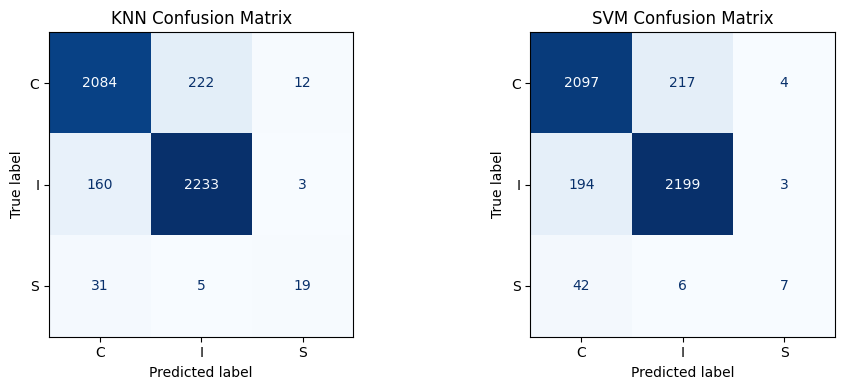

In [163]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(y_test, knn_preds, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('KNN Confusion Matrix')

ConfusionMatrixDisplay.from_predictions(y_test, svm_preds, ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('SVM Confusion Matrix')

plt.tight_layout()
plt.show()

KNN: achieved 91% overall accuracy and performed well on the majority classes (C and I), but struggled with the minority class S due to a severe class imbalance, correctly identifying only 35% of its samples.

SVM: achieved 90% overall accuracy (improving thanks to the 158 PCA components) but still struggled significantly to detect the minority class S (only 13% recall), as the margin-based algorithm prioritized the majority classes.

Overall: both models frequently confused classes C and I, confirming their high morphological similarity. Also, the severe class imbalance hindered the accurate prediction of class S. Nevertheless, KNN's local neighborhood approach still handled the rare minority class better than SVM.

## 5. Perform clustering analysis using 2 distict methods and compare clustring results with present labels.

In [164]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca_valid)


In [165]:
agglo = AgglomerativeClustering(n_clusters=3, linkage='ward')
agglo_labels = agglo.fit_predict(X_pca_valid)

In [166]:
comparison_df = pd.DataFrame({
    'True_Label': y_valid,
    'KMeans_Cluster': kmeans_labels,
    'Agglo_Cluster': agglo_labels
})

In [167]:
print("K-Means Clusters vs True Labels")
print(pd.crosstab(comparison_df['True_Label'], comparison_df['KMeans_Cluster']))

print("\nAgglomerative Clusters vs True Labels")
print(pd.crosstab(comparison_df['True_Label'], comparison_df['Agglo_Cluster']))

K-Means Clusters vs True Labels
KMeans_Cluster     0     1     2
True_Label                      
C               6205  1274  4112
I               6899  2262  2816
S                114     0   162

Agglomerative Clusters vs True Labels
Agglo_Cluster     0     1     2
True_Label                     
C              6303  1028  4260
I              4496  2015  5466
S               239     0    37


In [168]:
print(f"K-Means -> ARI: {adjusted_rand_score(y_valid, kmeans_labels):.4f}, NMI: {normalized_mutual_info_score(y_valid, kmeans_labels):.4f}")
print(f"Agglo   -> ARI: {adjusted_rand_score(y_valid, agglo_labels):.4f}, NMI: {normalized_mutual_info_score(y_valid, agglo_labels):.4f}")

K-Means -> ARI: 0.0115, NMI: 0.0173
Agglo   -> ARI: 0.0175, NMI: 0.0240


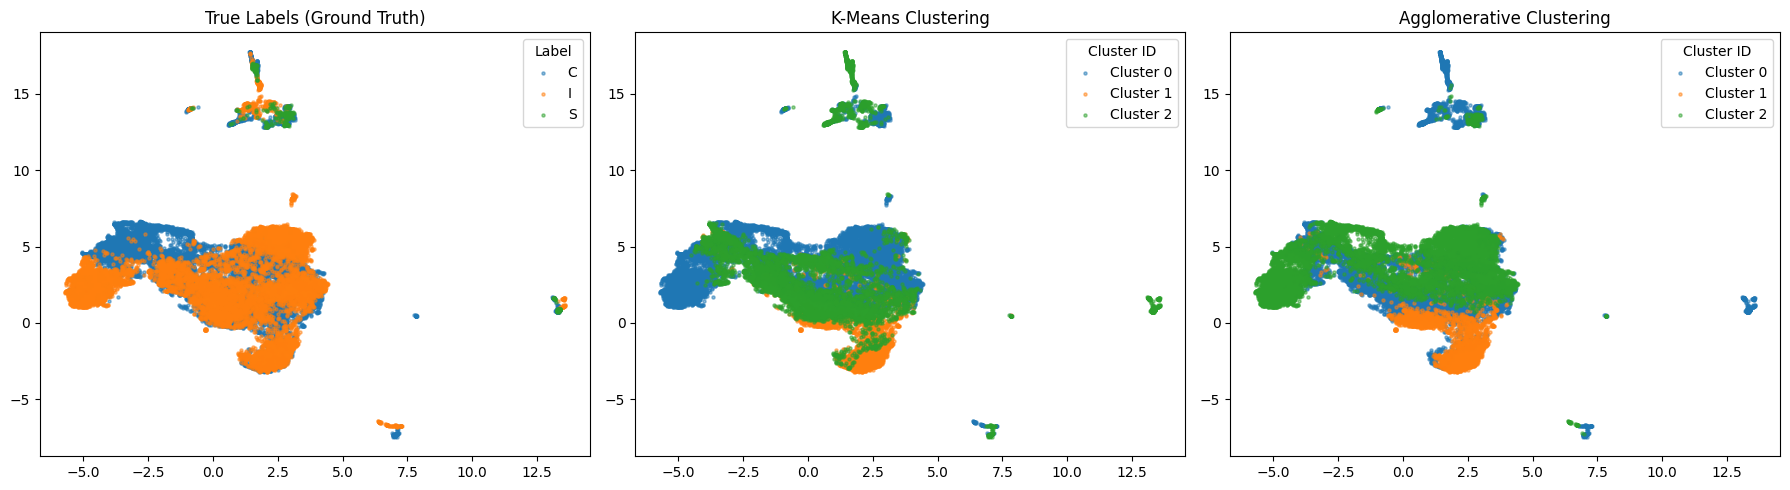

In [169]:
# Visual Comparison using UMAP
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# True Labels
for lbl in np.unique(y_valid):
    mask = (y_valid == lbl)
    axes[0].scatter(X_umap_valid[mask, 0], X_umap_valid[mask, 1], alpha=0.5, s=5, label=lbl)
axes[0].set_title('True Labels (Ground Truth)')
axes[0].legend(title='Label')

# K-Means
for cluster in np.unique(kmeans_labels):
    mask = (kmeans_labels == cluster)
    axes[1].scatter(X_umap_valid[mask, 0], X_umap_valid[mask, 1], alpha=0.5, s=5, label=f"Cluster {cluster}")
axes[1].set_title('K-Means Clustering')
axes[1].legend(title='Cluster ID')

# Agglomerative
for cluster in np.unique(agglo_labels):
    mask = (agglo_labels == cluster)
    axes[2].scatter(X_umap_valid[mask, 0], X_umap_valid[mask, 1], alpha=0.5, s=5, label=f"Cluster {cluster}")
axes[2].set_title('Agglomerative Clustering')
axes[2].legend(title='Cluster ID')

plt.tight_layout()
plt.show()

K-Means: failed to reconstruct the true biological labels. It randomly scattered the major classes (C and I) across all three computed clusters. As a result we got near-zero ARI (0.0115).   

Agglomerative Clustering: performed just as bad as k-means with little bit higher ARI score (0.0175), simply slicing the large central cloud of data into some pieces based on distance.   

Overral, the performance metrics and cross-tabulations proved that unsupervised clustering methods cannot separate the overlapping biological labels here, as the algorithms end up clustering the dominant technical noise rather than the actual biological signal.  

In [170]:
# Batch Effect Proof
print("K-Means Clusters vs Source")
print(pd.crosstab(metadata[source_col], comparison_df['KMeans_Cluster']))

K-Means Clusters vs Source
KMeans_Cluster                            0     1     2
./all_sources_isc_vgg_embeddings.csv                   
alamar                                  266     0   287
chroma                                    0     0    13
jimt                                  12378  3536  5934
mtt                                      56     0   373
study18                                 517     0   483


This cross-tabulation proves that the algorithm grouped the cells by their source file rather than their actual biological state, isolating the massive jimt batch entirely into its own cluster.

## 6. Try to decode label meaning

In [171]:
print(df_clean.groupby('label')['Value'].describe())

       count        mean        std     min         25%         50%  \
label                                                                 
C      542.0  133.057841  43.289625  90.220  101.555000  117.488889   
I      366.0   23.301403  17.626274   2.454   10.050000   14.750000   
S       74.0   79.910811   5.119226  70.030   74.848889   78.890000   

              75%         max  
label                          
C      151.700000  271.664444  
I       32.045000   69.730000  
S       83.427778   89.970000  


In [172]:
print(pd.crosstab(df_clean[source_col], df_clean['label']))

label                                     C      I    S
./all_sources_isc_vgg_embeddings.csv                   
alamar                                  307    230   16
chroma                                    4      5    4
jimt                                  10464  11384    0
mtt                                     235    136   58
study18                                 581    222  198


/tmp/ipykernel_1470/1538450010.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='Value', data=df_clean, palette='Set2')


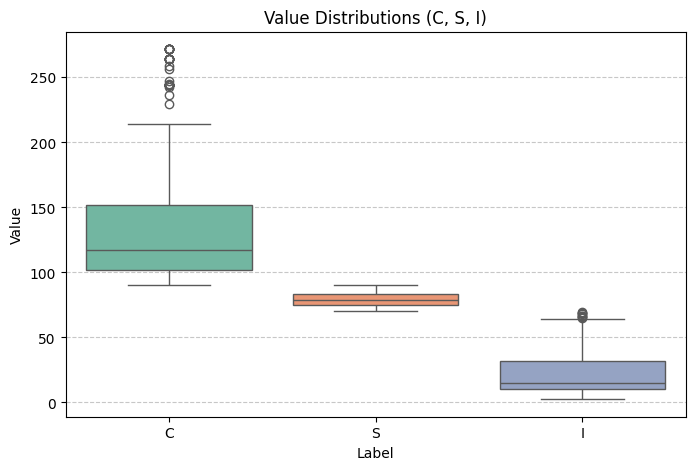

In [173]:
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(x='label', y='Value', data=df_clean, palette='Set2')
plt.title('Value Distributions (C, S, I)')
plt.xlabel('Label')
plt.ylabel('Value')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

C (Control): the highest values (mean ~133) and the largest spread, representing healthy, untreated cells.   

I (Inhibited): the lowest values (mean ~23), indicating heavily treated or dying cells.   

S (Specific): a specific intermediate cell state with stable, average values (mean ~80). Crucially, the cross-tabulation reveals that this group is completely absent from the largest data batch (jimt). This explains the severe class imbalance that caused models (especially SVM) to fail at predicting class S.   